In [50]:
!pip -q install ultralytics requests

In [ ]:
import cv2
import numpy as np
import base64
import requests
import re
import html

from IPython.display import display, Javascript, HTML
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from ultralytics import YOLO

In [ ]:
def take_photo():

    js = Javascript("""
    async function takePhoto() {

        const div = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        button.textContent = '📸 Capture Food Image';

        div.style.padding = '15px';
        div.style.textAlign = 'center';

        video.style.width = '100%';
        video.style.maxWidth = '600px';
        video.style.borderRadius = '12px';

        button.style.padding = '12px 22px';
        button.style.margin = '12px';
        button.style.borderRadius = '8px';
        button.style.border = 'none';
        button.style.background = '#2563eb';
        button.style.color = 'white';
        button.style.cursor = 'pointer';

        div.appendChild(video);
        div.appendChild(button);

        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => {
            button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(
            video, 0, 0
        );

        stream.getTracks().forEach(track => track.stop());

        div.remove();

        return canvas.toDataURL('image/jpeg');
    }
    """)

    display(js)

    return eval_js("takePhoto()")


photo = take_photo()

image_bytes = base64.b64decode(photo.split(',')[1])

image_array = np.frombuffer(
    image_bytes,
    dtype=np.uint8
)

frame = cv2.imdecode(
    image_array,
    cv2.IMREAD_COLOR
)

if frame is None:
    raise ValueError("Image capture failed.")

In [49]:
model = YOLO("yolo11n.pt")

results = model.predict(
    source=frame,
    conf=0.25,
    imgsz=640
)

COCO_FOOD_LABELS = {
    "apple",
    "banana",
    "broccoli",
    "carrot",
    "sandwich",
    "pizza",
    "hot dog",
    "cake",
    "donut"
}

detected_foods = []

for result in results:

    for box in result.boxes:

        class_id = int(box.cls[0])

        label = model.names[class_id]

        if label in COCO_FOOD_LABELS:

            confidence = float(box.conf[0])

            detected_foods.append({
                "name": label,
                "confidence": confidence
            })


print("Food detection completed!")


0: 480x640 1 orange, 1 carrot, 152.5ms
Speed: 4.1ms preprocess, 152.5ms inference, 3.7ms postprocess per image at shape (1, 3, 480, 640)
Food detection completed!


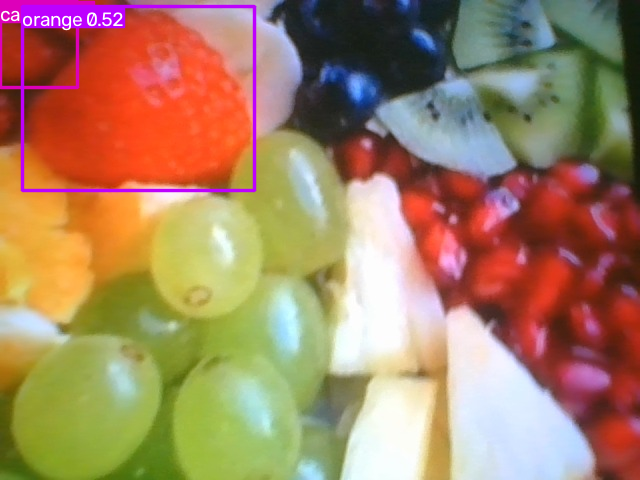

In [48]:
annotated_image = results[0].plot()

display(HTML("""
<div style="
    text-align:center;
    padding:15px;
    font-family:Arial;
">
    <h2 style="color:#2563eb;">
        📷 Food Detection Result
    </h2>
    <p style="color:#64748b;">
        Your captured image with detected food labels.
    </p>
</div>
"""))

cv2_imshow(annotated_image)

In [47]:
API_KEY = "DEMO_KEY"

BASE_URL = "https://api.nal.usda.gov/fdc/v1"


def normalize_name(name):

    return re.sub(
        r'[^a-z0-9 ]',
        '',
        name.lower()
    ).strip()


def search_usda(food_name):

    url = f"{BASE_URL}/foods/search"

    params = {
        "query": food_name,
        "pageSize": 10,
        "api_key": API_KEY,
        "dataType": ["Foundation", "SR Legacy"]
    }

    try:

        response = requests.get(
            url,
            params=params,
            timeout=15
        )

        response.raise_for_status()

        foods = response.json().get("foods", [])

        if not foods:
            return None

        target = normalize_name(food_name)

        best_food = None
        best_score = -1

        for food in foods:

            description = normalize_name(
                food.get("description", "")
            )

            score = 0

            if description == target:
                score += 100

            elif target in description:
                score += 50

            elif description in target:
                score += 40

            target_words = set(target.split())
            description_words = set(description.split())

            score += len(
                target_words.intersection(description_words)
            ) * 10

            if score > best_score:

                best_score = score
                best_food = food

        return best_food

    except requests.exceptions.RequestException:
        return None

    except (ValueError, TypeError, KeyError):
        return None


def get_food_details(fdc_id):

    url = f"{BASE_URL}/food/{fdc_id}"

    params = {
        "api_key": API_KEY
    }

    try:

        response = requests.get(
            url,
            params=params,
            timeout=15
        )

        response.raise_for_status()

        return response.json()

    except requests.exceptions.RequestException:
        return None

    except (ValueError, TypeError):
        return None


print("USDA connection functions are ready.")

USDA connection functions are ready.


In [46]:
def extract_nutrients(food_data):

    nutrients = {}

    for item in food_data.get("foodNutrients", []):

        nutrient = item.get("nutrient", item)

        name = nutrient.get("name")

        amount = item.get(
            "amount",
            nutrient.get("amount")
        )

        unit = item.get(
            "unitName",
            nutrient.get("unitName", "")
        )

        if name and amount is not None:

            nutrients[name.lower()] = {
                "amount": amount,
                "unit": unit
            }

    return nutrients

In [45]:
NUTRIENT_CATEGORIES = {

    "Carbohydrates": [
        "carbohydrate, by difference"
    ],

    "Protein": [
        "protein"
    ],

    "Fats": [
        "total lipid (fat)"
    ],

    "Fibre": [
        "fiber, total dietary"
    ],

    "Vitamins": [
        "vitamin a, rae",
        "vitamin c, total ascorbic acid",
        "vitamin d (d2 + d3)",
        "vitamin e (alpha-tocopherol)",
        "vitamin k (phylloquinone)",
        "thiamin",
        "riboflavin",
        "niacin",
        "vitamin b-6",
        "folate, total"
    ],

    "Minerals": [
        "calcium, ca",
        "iron, fe",
        "magnesium, mg",
        "phosphorus, p",
        "potassium, k",
        "sodium, na",
        "zinc, zn"
    ]
}

In [44]:

# ==========================================
# SMART PLATE - FINAL RESULTS DASHBOARD
# ==========================================

from IPython.display import display, HTML
import html

# Check required variables and functions
required_items = [
    "detected_foods",
    "search_usda",
    "get_food_details",
    "extract_nutrients",
    "NUTRIENT_CATEGORIES"
]

missing_items = [
    item for item in required_items
    if item not in globals()
]

if missing_items:
    raise RuntimeError(
        "Please run the earlier project cells first. "
        "Missing: " + ", ".join(missing_items)
    )


def display_header():

    display(HTML("""
    <div style="
        background:linear-gradient(135deg,#164e63,#2563eb);
        padding:28px;
        border-radius:16px;
        color:white;
        font-family:Arial;
        text-align:center;
        margin:15px 0;
    ">
        <h1 style="margin:0;font-size:30px;">
            🍽️ SMART PLATE
        </h1>
        <p>Food Item Detection and Identification</p>
        <p style="font-size:12px;">
            Computer Vision | YOLO11
        </p>
    </div>
    """))


def display_food_card(food):

    name = html.escape(food["name"].title())

    confidence = max(
        0,
        min(100, round(food["confidence"] * 100, 2))
    )

    display(HTML(f"""
    <div style="
        background:#f0fdf4;
        border:1px solid #bbf7d0;
        border-radius:12px;
        padding:16px;
        margin:10px 0;
        font-family:Arial;
    ">
        <h3 style="color:#166534;margin:0 0 8px;">
            🥗 {name}
        </h3>
        <p style="color:#475569;">
            Detection confidence: <b>{confidence}%</b>
        </p>
        <div style="background:#dcfce7;height:8px;border-radius:10px;">
            <div style="
                background:#16a34a;
                width:{confidence}%;
                height:8px;
                border-radius:10px;
            "></div>
        </div>
    </div>
    """))


def unavailable_message():

    display(HTML("""
    <p style="
        background:#fffbeb;
        color:#92400e;
        padding:12px;
        border-radius:8px;
    ">
        Nutrition information is temporarily unavailable.
    </p>
    """))


def display_nutrition(food_name):

    try:

        matched_food = search_usda(food_name)

        if not matched_food:
            unavailable_message()
            return

        details = get_food_details(
            matched_food["fdcId"]
        )

        if not details:
            unavailable_message()
            return

        nutrients = extract_nutrients(details)

        match_name = html.escape(
            matched_food.get("description", "Unknown")
        )

        display(HTML(f"""
        <div style="
            background:#eff6ff;
            border-radius:10px;
            padding:14px;
            margin:12px 0;
            font-family:Arial;
        ">
            <b style="color:#1d4ed8;">USDA food record</b>
            <p>{match_name}</p>
        </div>
        """))

        for category, nutrient_names in NUTRIENT_CATEGORIES.items():

            rows = ""

            for nutrient_name in nutrient_names:

                value = nutrients.get(nutrient_name)

                if value is not None:

                    safe_name = html.escape(
                        nutrient_name.title()
                    )

                    safe_unit = html.escape(
                        str(value["unit"])
                    )

                    rows += f"""
                    <tr>
                        <td style="padding:8px;border-bottom:1px solid #e2e8f0;">
                            {safe_name}
                        </td>
                        <td style="padding:8px;text-align:right;">
                            {value["amount"]} {safe_unit}
                        </td>
                    </tr>
                    """

            if rows:

                display(HTML(f"""
                <div style="
                    border:1px solid #e2e8f0;
                    border-radius:10px;
                    padding:12px;
                    margin:10px 0;
                    font-family:Arial;
                ">
                    <h4 style="color:#2563eb;">
                        {html.escape(category)}
                    </h4>
                    <table style="width:100%;border-collapse:collapse;">
                        {rows}
                    </table>
                </div>
                """))

    except Exception:
        unavailable_message()


# ==========================================
# DISPLAY FINAL RESULTS
# ==========================================

display_header()

if not detected_foods:

    display(HTML("""
    <div style="
        padding:18px;
        background:#fff7ed;
        border-radius:12px;
        color:#9a3412;
        font-family:Arial;
    ">
        <h3>No supported food items detected.</h3>
        <p>Try capturing a clearer image with good lighting.</p>
    </div>
    """))

else:

    display(HTML("""
    <h2 style="color:#2563eb;font-family:Arial;">
        Detected Food Items
    </h2>
    """))

    for food in detected_foods:
        display_food_card(food)

    display(HTML("""
    <h2 style="color:#2563eb;font-family:Arial;">
        📊 Nutrition Database References
    </h2>
    """))

    for food in detected_foods:

        display(HTML(f"""
        <h3 style="font-family:Arial;color:#166534;">
            {html.escape(food["name"].title())}
        </h3>
        """))

        display_nutrition(food["name"])


display(HTML("""
<div style="
    background:#f1f5f9;
    border-radius:12px;
    padding:18px;
    margin-top:25px;
    font-family:Arial;
    color:#475569;
">
    <h3 style="color:#1e293b;">
        Smart Plate Project Completed
    </h3>
    <p>Food identification is performed using YOLO11.</p>
    <p>USDA nutrition references are displayed when available.</p>
    <p>Values are database references, not measured food portions.</p>
    <p>No portion estimation or plate nutrition total is calculated.</p>
</div>
"""))
